# 3. Smoothness and spectral accuracy

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/spectral-methods-in-python/blob/main/notebooks/03_smoothness_and_spectral_accuracy.ipynb)

*Companion to Chapter 4 of L. N. Trefethen, Spectral Methods in MATLAB (SIAM, 2000).*

In notebook 1 the error of the spectral derivative of the piston motion fell like $e^{-0.88N}$,
and the number 0.88 was announced without explanation. This notebook supplies the explanation.
The accuracy of a spectral method is decided by one property of the function being
differentiated, its **smoothness**, and the link between the two is the rate at which the
Fourier coefficients decay. Once the link is understood, the convergence rate can be predicted
before any computation is run.

You will see:

- four degrees of smoothness and the coefficient decay that goes with each
- the aliasing formula, which turns coefficient decay into grid error
- a convergence rate read off from the position of a singularity in the complex plane
- the Gibbs phenomenon: what a jump does to a Fourier approximation

**Worked examples:** the piston of notebook 1 explained, and the follower acceleration of two
cams, one with dwells and one without.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import sici

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

In [2]:
# fft_derivative(v, order) from notebook 2
def fft_derivative(v, order=1):
    """Spectral derivative of real periodic samples v on the grid x_j = 2πj/N."""
    N = len(v)
    k = np.fft.fftfreq(N, d=1 / N)
    factor = (1j * k) ** order
    if order % 2 and N % 2 == 0:
        factor[N // 2] = 0                                     # the Nyquist mode, see notebook 2
    return np.real(np.fft.ifft(factor * np.fft.fft(v)))

# fourier_interpolate(v, M) from notebook 2
def fourier_interpolate(v, M):
    """Values of the trigonometric interpolant of v (N samples, N even) on the periodic grid of M > N points."""
    N = len(v)
    v_hat = np.fft.fft(v)
    padded = np.zeros(M, dtype=complex)
    padded[: N // 2] = v_hat[: N // 2]                         # k = 0, ..., N/2 - 1
    padded[M - N // 2 + 1 :] = v_hat[N // 2 + 1 :]             # k = -N/2 + 1, ..., -1
    padded[N // 2] = padded[M - N // 2] = v_hat[N // 2] / 2    # the Nyquist mode, shared between ±N/2
    return np.real(np.fft.ifft(padded)) * M / N

def fourier_grid(N):
    """Equispaced periodic grid on [0, 2*pi): x_j = 2*pi*j/N, j = 0..N-1."""
    return 2 * np.pi * np.arange(N) / N

## 3.1 Fourier coefficients

A $2\pi$-periodic function $u$ can be written as a sum of waves,

$$u(x) = \sum_{k=-\infty}^{\infty} c_k\,e^{ikx},\qquad c_k = \frac{1}{2\pi}\int_0^{2\pi} u(x)\,e^{-ikx}\,dx .$$

The $c_k$ are the **Fourier coefficients** of the function itself. They are not the same as the
discrete amplitudes $\hat v_k$ that the FFT computes from $N$ samples (section 3.3 gives the
exact relation), but on a fine grid the two agree closely: $\hat v_k/N$ is the trapezoidal rule
applied to the integral. That gives a practical way to compute them.

In [3]:
def fourier_coefficients(u, M=4096):
    """Approximate Fourier coefficients c_k of the function u, in np.fft.fftfreq order, from M samples."""
    return np.fft.fft(u(fourier_grid(M))) / M

**How smoothness controls the decay: two arguments by hand.**

*Integrate by parts.* Since $e^{-ikx}$ is the derivative of $e^{-ikx}/(-ik)$, and the boundary
terms cancel by periodicity,

$$c_k = \frac{1}{2\pi}\int_0^{2\pi} u\,e^{-ikx}\,dx = \frac{1}{ik}\cdot\frac{1}{2\pi}\int_0^{2\pi} u'\,e^{-ikx}\,dx .$$

Each derivative that exists buys one factor of $1/k$. The process stops at the first derivative
that has jumps, say $u^{(p)}$. One more integration by parts is still possible piece by piece,
and it leaves the jumps behind as boundary terms. So $|c_k|$ falls like $|k|^{-(p+1)}$, with a
constant proportional to the size of the jumps of $u^{(p)}$.

*Shift the path of integration.* Suppose $u$ has no singularities at all for complex $x$ within a
distance $a$ of the real axis. Such a function is called **analytic** in the strip
$|\operatorname{Im}x| < a$. Then the integral may be taken along the line $x = t - ia'$ with any
$a' < a$ instead (for $k > 0$; upwards for $k < 0$). On that line
$|e^{-ikx}| = e^{-a'k}$, so $|c_k|$ is at most $e^{-a'|k|}$ times the largest value of $|u|$
on the line. The coefficients decay **geometrically**, at a rate set by the distance $a$ to the
nearest singularity.

## 3.2 Four degrees of smoothness

| | Smoothness of $u$ | Fourier coefficients | Error of the spectral $\nu$-th derivative |
| --- | --- | --- | --- |
| (a) | $p-1$ continuous derivatives, and a $p$-th derivative that is bounded but jumps | $O(\lvert k\rvert^{-(p+1)})$ | algebraic, $O(N^{-(p-\nu)})$ |
| (b) | infinitely many derivatives, but not analytic: a singularity on the real axis that no derivative reveals | faster than any power of $1/\lvert k\rvert$ | faster than any power of $1/N$ |
| (c) | analytic in the strip $\lvert\operatorname{Im}x\rvert < a$ of the complex plane | $O(e^{-a'\lvert k\rvert})$ for every $a' < a$ | geometric, about $e^{-aN/2}$ |
| (d) | band-limited: a finite sum of waves, $\lvert k\rvert \le K$ | zero for $\lvert k\rvert > K$ | zero for $N > 2K$ |

(The precise condition in row (a) is that $u^{(p)}$ has bounded variation, which covers every
piecewise smooth function with a finite number of finite jumps.) The last column is derived in 3.3 and tested
in 3.4. The middle column is tested now, on four functions chosen to represent the four rows.

| | Function on $[0, 2\pi)$ | Why it belongs to its row |
| --- | --- | --- |
| $f_1$ | $\max(0, \cos x)^3$ | third derivative jumps by 6 at $x = \pi/2$ and $3\pi/2$, so $p = 3$ |
| $f_2$ | $\exp\!\Big(\dfrac{-1}{1 - ((x-\pi)/\pi)^2}\Big)$, and 0 at $x = 0$ | every derivative exists, also at $x = 0$ where they all vanish, but it is not analytic there |
| $f_3$ | $\dfrac{1}{2 - \cos x}$ | analytic on the real axis, poles where $\cos x = 2$, at $x = \pm i\,\mathrm{arccosh}\,2$ |
| $f_4$ | $\cos 8x + \sin 3x$ | band-limited with $K = 8$ |

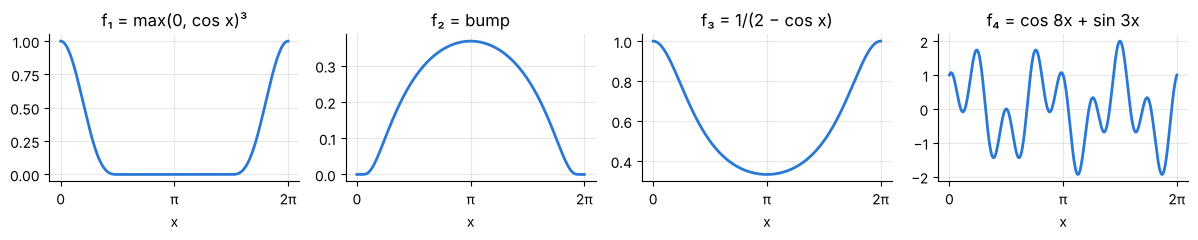

In [4]:
def periodic_bump(x):
    t = (np.mod(x, 2 * np.pi) - np.pi) / np.pi
    safe = np.where(np.abs(t) < 1, 1 - t**2, 1.0)
    return np.where(np.abs(t) < 1, np.exp(-1 / safe), 0.0)

def periodic_bump_derivative(x):
    t = (np.mod(x, 2 * np.pi) - np.pi) / np.pi
    safe = np.where(np.abs(t) < 1, 1 - t**2, 1.0)
    return np.where(np.abs(t) < 1, -2 * t / (np.pi * safe**2) * np.exp(-1 / safe), 0.0)

tests = {            # name: (function, exact first derivative)
    "f₁ = max(0, cos x)³": (lambda x: np.maximum(0, np.cos(x)) ** 3, lambda x: -3 * np.maximum(0, np.cos(x)) ** 2 * np.sin(x)),
    "f₂ = bump": (periodic_bump, periodic_bump_derivative),
    "f₃ = 1/(2 − cos x)": (lambda x: 1 / (2 - np.cos(x)), lambda x: -np.sin(x) / (2 - np.cos(x)) ** 2),
    "f₄ = cos 8x + sin 3x": (lambda x: np.cos(8 * x) + np.sin(3 * x), lambda x: -8 * np.sin(8 * x) + 3 * np.cos(3 * x)),
}
f1, f2, f3, f4 = (pair[0] for pair in tests.values())

fine = np.linspace(0, 2 * np.pi, 600)
fig, axes = plt.subplots(1, 4, figsize=(12, 2.5))
for ax, (name, (f, _)) in zip(axes, tests.items()):
    ax.plot(fine, f(fine))
    ax.set(title=name, xlabel="x", xticks=[0, np.pi, 2 * np.pi], xticklabels=["0", "π", "2π"])
fig.tight_layout()

To the eye the first three are equally smooth. Their coefficients tell them apart.

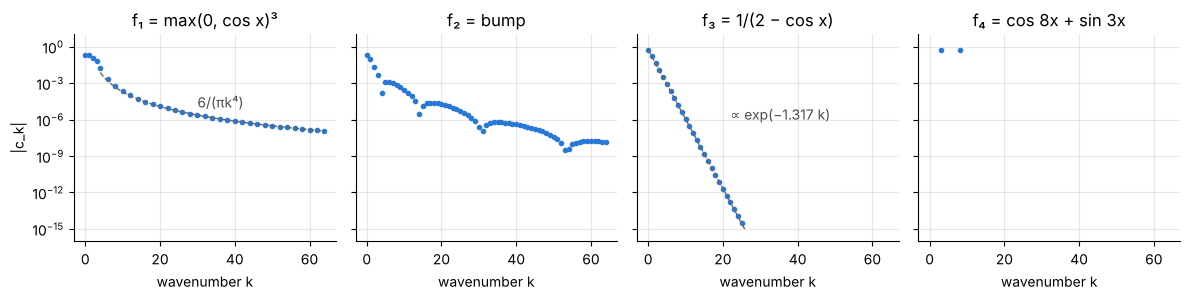

In [5]:
a_strip = np.arccosh(2.0)                                      # distance of the poles of f₃ from the real axis
k_plot = np.arange(0, 65)
coefficients = {name: np.abs(fourier_coefficients(f))[k_plot] for name, (f, _) in tests.items()}

fig, axes = plt.subplots(1, 4, figsize=(12, 3.1), sharey=True)
for ax, (name, c) in zip(axes, coefficients.items()):
    visible = c > 1e-15                                        # anything smaller is rounding error, in effect zero
    ax.semilogy(k_plot[visible], c[visible], "o", ms=3)
    ax.set(title=name, xlabel="wavenumber k", xlim=(-3, 67), ylim=(1e-16, 10))
axes[0].semilogy(k_plot[4:], 6 / (np.pi * k_plot[4:] ** 4.0), "--", color="0.4", lw=1)
axes[0].annotate("6/(πk⁴)", xy=(30, 1e-5), color="0.3")
axes[2].semilogy(k_plot[:27], np.exp(-a_strip * k_plot[:27]) / np.sqrt(3), "--", color="0.4", lw=1)
axes[2].annotate("∝ exp(−1.317 k)", xy=(22, 1e-6), color="0.3")
axes[0].set_ylabel("|c_k|")
fig.tight_layout()

On these axes, logarithmic in $|c_k|$ and linear in $k$, geometric decay is a straight line
($f_3$), algebraic decay a curve that flattens out ($f_1$), and the infinitely differentiable
$f_2$ lies in between: it bends away from every straight line but beats every power in the long
run. The band-limited $f_4$ has two non-zero coefficients in the range shown, at $k = 3$ and
$k = 8$ (and their mirror images at negative $k$). Values below $10^{-15}$ are rounding errors
and are not drawn.

**Verify** the two cases where the theory gives numbers.

For $f_3$ the coefficients are known exactly, $c_k = \dfrac{1}{\sqrt3}\,(2 - \sqrt3)^{|k|}$. Since
$2 - \sqrt3 = e^{-\mathrm{arccosh}\,2}$, the decay rate is $a = \mathrm{arccosh}\,2 = \ln(2 + \sqrt3) = 1.31696$,
the distance of the poles from the real axis, as the contour argument promised.

For $f_1$ the integration by parts can be carried to the end. The third derivative jumps by 6
at two points, and for even $k$ the two contributions add up to $|c_k| \approx 6/(\pi k^4)$.
For odd $k > 3$ they cancel and the coefficients vanish.

In [6]:
c3 = fourier_coefficients(f3, 128)
k = np.fft.fftfreq(128, 1 / 128)
exact_c3 = (2 - np.sqrt(3)) ** np.abs(k) / np.sqrt(3)
print(f"f₃: largest error of the computed coefficients {np.abs(c3 - exact_c3).max():.1e}")
assert np.abs(c3 - exact_c3).max() < 1e-13
assert np.isclose(a_strip, np.log(2 + np.sqrt(3))) and abs(a_strip - 1.31696) < 1e-5
assert abs(2 - np.cos(1j * a_strip)) < 1e-14                   # the pole: cos(ia) = cosh(a) = 2

c1 = np.abs(fourier_coefficients(f1, 2**14))
even = np.arange(8, 200, 2)
decay_order = -np.polyfit(np.log(even), np.log(c1[even]), 1)[0]
print(f"f₁: fitted decay order of the even coefficients {decay_order:.3f}, |c_64| 64⁴ = {c1[64] * 64**4:.4f}, 6/π = {6 / np.pi:.4f}")
assert abs(decay_order - 4) < 0.05 and abs(c1[64] * 64**4 / (6 / np.pi) - 1) < 0.01
assert c1[np.arange(5, 200, 2)].max() < 1e-12                  # odd coefficients beyond k = 3 vanish

c4 = np.abs(fourier_coefficients(f4, 64))
assert np.allclose(c4[[3, 8]], 0.5) and np.delete(c4[:33], [3, 8]).max() < 1e-14

f₃: largest error of the computed coefficients 1.1e-16
f₁: fitted decay order of the even coefficients 4.020, |c_64| 64⁴ = 1.9145, 6/π = 1.9099


## 3.3 From coefficients to grid errors: the aliasing formula

A spectral method never sees the $c_k$. It sees $N$ samples, and from them the discrete
amplitudes $\hat v_k$.

**By hand.** Insert the Fourier series of $u$ into the definition of the DFT. By notebook 2 all
the waves with wavenumbers $k, k \pm N, k \pm 2N, \dots$ have the same samples as $e^{ikx}$, so
their coefficients are added together:

$$\frac{\hat v_k}{N} = \sum_{m=-\infty}^{\infty} c_{k+mN} = c_k + (c_{k+N} + c_{k-N}) + (c_{k+2N} + c_{k-2N}) + \dots$$

This is the **aliasing formula**. The interpolant used by the spectral method is built from
the $\hat v_k/N$ with $|k| \le N/2$, where the function is built from all the $c_k$. The two
differ in two ways: the interpolant lacks the waves beyond $N/2$ (truncation), and its
amplitudes are polluted by those same missing coefficients (aliasing). Both parts consist of
the coefficients beyond $N/2$ and nothing else, so

$$\text{error of the interpolant} \;\le\; 2\sum_{|k| \ge N/2} |c_k|,\qquad
\text{error of its derivative} \;\lesssim\; 2\sum_{|k| \ge N/2} |k|\,|c_k| .$$

That gives the last column of the table in 3.2. If $|c_k| \sim e^{-a|k|}$ the sum is dominated
by its first term and the error is about $e^{-aN/2}$, times a factor of order $N$ for the
derivative. If $|c_k| \sim |k|^{-(p+1)}$ the sum for the $\nu$-th derivative behaves like
$N^{-(p-\nu)}$. If the coefficients vanish beyond $K$, the error is zero once $N/2 > K$.

**Verify** the formula on $f_3$, whose coefficients are known, with only $N = 16$ samples.

In [7]:
N = 16
k = np.fft.fftfreq(N, 1 / N)
exact_c = lambda k: (2 - np.sqrt(3)) ** np.abs(k) / np.sqrt(3)
aliased_sum = sum(exact_c(k + m * N) for m in range(-6, 7))
discrete = np.fft.fft(f3(fourier_grid(N))) / N
assert np.abs(discrete - aliased_sum).max() < 1e-14
print(f"k = 6:  c_k = {exact_c(6):.3e}   discrete amplitude / N = {discrete[6].real:.3e}   c_6 + c_(-10) = {exact_c(6) + exact_c(-10):.3e}")

k = 6:  c_k = 2.137e-04   discrete amplitude / N = 2.148e-04   c_6 + c_(-10) = 2.148e-04


## 3.4 Convergence of the spectral derivative

Now the test that matters: differentiate each function with `fft_derivative` and measure the
largest error on the grid, for even $N$ up to 200.

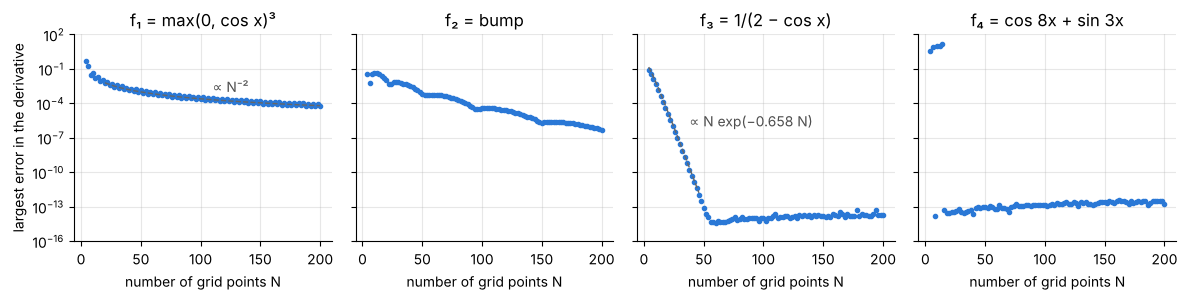

In [8]:
def derivative_error(u, du, N, order=1):
    x = fourier_grid(N)
    return np.abs(fft_derivative(u(x), order) - du(x)).max()

N_values = np.arange(4, 201, 2)
errors = {name: np.array([derivative_error(f, df, N) for N in N_values]) for name, (f, df) in tests.items()}

fig, axes = plt.subplots(1, 4, figsize=(12, 3.1), sharey=True)
for ax, (name, err) in zip(axes, errors.items()):
    ax.semilogy(N_values, np.maximum(err, 1e-17), "o", ms=3)
    ax.set(title=name, xlabel="number of grid points N", ylim=(1e-16, 1e2))
axes[0].semilogy(N_values[8:], 2.5 / N_values[8:] ** 2.0, "--", color="0.4", lw=1)
axes[0].annotate("∝ N⁻²", xy=(110, 1e-3), color="0.3")
axes[2].semilogy(N_values[:22], 0.5 * N_values[:22] * np.exp(-a_strip * N_values[:22] / 2), "--", color="0.4", lw=1)
axes[2].annotate("∝ N exp(−0.658 N)", xy=(38, 1e-6), color="0.3")
axes[0].set_ylabel("largest error in the derivative")
fig.tight_layout()

Each error curve is the coefficient curve above it with the horizontal axis stretched by two,
as the aliasing formula says: the error at $N$ points is governed by the coefficients near
$k = N/2$.

**Verify the predicted rates.**

- $f_3$: the error should behave like $N e^{-aN/2}$ with $a/2 = 0.658$. The fit divides out
  the factor $N$.
- $f_1$: here $p = 3$ and $\nu = 1$, so the prediction is $N^{-(p-\nu)} = N^{-2}$. In words:
  the coefficients of $f_1'$ decay like $k^{-3}$, and the sum of $k^{-3}$ beyond $N/2$ is
  proportional to $N^{-2}$.
- $f_4$: exact once the grid can represent wavenumber 8.

In [9]:
analytic = errors["f₃ = 1/(2 − cos x)"]
window = (N_values >= 8) & (N_values <= 44)                    # before rounding errors take over
rate = -np.polyfit(N_values[window], np.log(analytic[window] / N_values[window]), 1)[0]
print(f"f₃: fitted decay rate {rate:.4f}   predicted a/2 = {a_strip / 2:.4f}")
assert abs(rate / (a_strip / 2) - 1) < 0.03

rough = errors["f₁ = max(0, cos x)³"]
late = N_values >= 20
order = -np.polyfit(np.log(N_values[late]), np.log(rough[late]), 1)[0]
print(f"f₁: observed algebraic order {order:.2f}   predicted 2")
assert abs(order - 2) < 0.3

band = dict(zip(N_values.tolist(), errors["f₄ = cos 8x + sin 3x"]))
print("f₄: " + "  ".join(f"N={N}: {band[N]:.0e}" for N in range(4, 23, 2)))
assert max(band[N] for N in range(16, 201, 2)) < 1e-10
assert min(band[N] for N in (4, 6, 10, 12, 14)) > 1

f₃: fitted decay rate 0.6578   predicted a/2 = 0.6585
f₁: observed algebraic order 2.00   predicted 2
f₄: N=4: 4e+00  N=6: 8e+00  N=8: 1e-14  N=10: 1e+01  N=12: 1e+01  N=14: 1e+01  N=16: 5e-14  N=18: 3e-14  N=20: 3e-14  N=22: 4e-14


All three predictions hold. Two entries of the $f_4$ list deserve a comment, because they show
how carefully "the grid can represent it" must be read.

- $N = 16$ is already exact, although wavenumber 8 is then the Nyquist wavenumber. The
  interpolant of notebook 2 contains the wave $\cos(Nx/2)$, so $\cos 8x$ is represented, and its
  derivative $-8\sin 8x$ vanishes at the grid points just as the Nyquist rule assumes. A
  $\sin 8x$ term would have been lost: it is zero at every grid point.
- $N = 8$ gives the right first derivative by accident. On 8 points $\cos 8x$ is aliased to the
  constant 1, whose derivative is zero, and the true derivative $-8\sin 8x$ also happens to be
  zero at those 8 points. The interpolant is wrong, and the second derivative exposes it.

In [10]:
second_derivative = lambda x: -64 * np.cos(8 * x) - 9 * np.sin(3 * x)
print(f"f₄, error of the second derivative: N = 8: {derivative_error(f4, second_derivative, 8, order=2):.1f}   "
      f"N = 16: {derivative_error(f4, second_derivative, 16, order=2):.1e}")
assert abs(derivative_error(f4, second_derivative, 8, order=2) - 64) < 1e-10
assert derivative_error(f4, second_derivative, 16, order=2) < 1e-11

f₄, error of the second derivative: N = 8: 64.0   N = 16: 3.6e-14


## 3.5 Worked example: the piston explained

**Problem.** Predict the rate $e^{-0.88N}$ at which the error of the piston velocity fell in
notebook 1, for $s(\theta) = r\cos\theta + \sqrt{l^2 - r^2\sin^2\theta}$ with $l/r = 3$.

**By hand.** For real $\theta$ the function is perfectly smooth, since $r\sin\theta$ never
reaches $l$. For complex $\theta$ it can: the square root has a branch point wherever its
argument is zero, that is where $\sin\theta = \pm l/r$. Try $\theta = \pi/2 + iy$. Then
$\sin\theta = \cosh y$, which equals $l/r$ at $y = \mathrm{arccosh}(l/r)$. So $s$ is analytic in
the strip of half-width

$$a = \mathrm{arccosh}\,\frac lr = \mathrm{arccosh}\,3 = 1.7627,$$

its coefficients decay like $e^{-1.7627|k|}$, and the error of the spectral derivative falls
like $e^{-aN/2} = e^{-0.881N}$.

decay rate of the velocity error: measured 0.881   predicted arccosh(3)/2 = 0.881


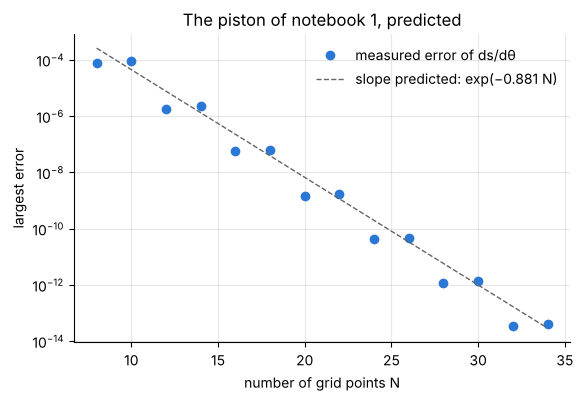

In [11]:
r_crank, l_rod = 1.0, 3.0

def position(theta):
    return r_crank * np.cos(theta) + np.sqrt(l_rod**2 - r_crank**2 * np.sin(theta) ** 2)

def velocity(theta):                        # ds/dθ, exact
    root = np.sqrt(l_rod**2 - r_crank**2 * np.sin(theta) ** 2)
    return -r_crank * np.sin(theta) - r_crank**2 * np.sin(theta) * np.cos(theta) / root

a_piston = np.arccosh(l_rod / r_crank)
branch_point = np.pi / 2 + 1j * a_piston
assert abs(l_rod**2 - r_crank**2 * np.sin(branch_point) ** 2) < 1e-13     # the square root vanishes there
assert abs(a_piston - 1.7627) < 1e-4

N_piston = np.arange(8, 35, 2)
piston_errors = np.array([derivative_error(position, velocity, N) for N in N_piston])
measured = -np.polyfit(N_piston, np.log(piston_errors), 1)[0]
print(f"decay rate of the velocity error: measured {measured:.3f}   predicted arccosh(3)/2 = {a_piston / 2:.3f}")
assert abs(measured / (a_piston / 2) - 1) < 0.05

fig, ax = plt.subplots()
ax.semilogy(N_piston, piston_errors, "o", label="measured error of ds/dθ")
ax.semilogy(N_piston, 0.3 * np.exp(-a_piston / 2 * N_piston), "--", color="0.4", lw=1, label="slope predicted: exp(−0.881 N)")
ax.set(xlabel="number of grid points N", ylabel="largest error", title="The piston of notebook 1, predicted")
ax.legend(frameon=False, loc="upper right");

The measured rate matches the prediction to better than one per cent. A convergence rate has
been computed with pencil and paper from the geometry of the mechanism. (The errors come in
pairs, $N = 4m$ and $4m + 2$, because the square-root term repeats twice per revolution and so
contains only even wavenumbers: the two extra points add the odd wavenumber $2m + 1$, which the
signal does not contain. No factor $N$ was divided out this time. At a square-root branch point the coefficients carry an extra factor
$|k|^{-3/2}$ on top of the geometric decay, which roughly cancels the factor from the
differentiation.)

What it means for design calculations: the smoothness that matters is not what the eye sees on
the real axis but the distance to the nearest singularity in the complex plane. A short
connecting rod ($l/r$ close to 1) brings the branch point close to the real axis: the motion
has a sharper feature near $\theta = 90°$, the strip is narrow, and more points are needed. For
$l/r = 1.5$ the rate drops to $e^{-0.48N}$, so the same accuracy takes nearly twice as many
points.

## 3.6 The Gibbs phenomenon

The table in 3.2 starts at continuous functions. One step rougher is a function that itself
jumps, such as the square wave $\operatorname{sign}(\sin x)$. Its Fourier series is
$\dfrac4\pi\big(\sin x + \tfrac13\sin 3x + \tfrac15\sin 5x + \dots\big)$, with coefficients that
decay only like $1/k$.

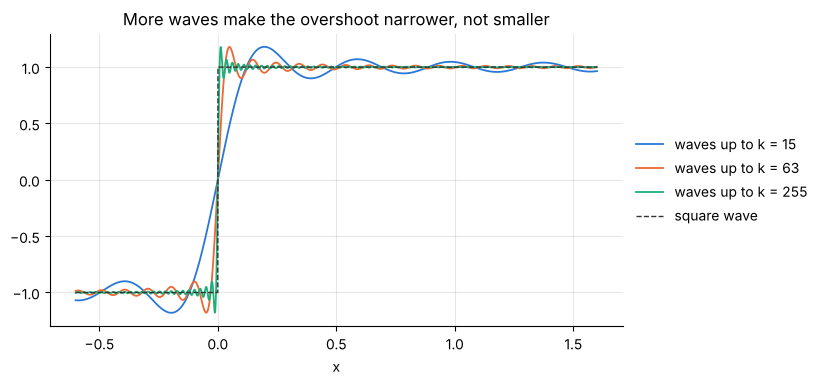

In [12]:
def square_wave_sum(x, n):
    """Fourier series of sign(sin x), summed up to wavenumber n."""
    k = np.arange(1, n + 1, 2)
    return 4 / np.pi * (np.sin(np.outer(x, k)) / k).sum(axis=1)

x_plot = np.linspace(-0.6, 1.6, 2400)
fig, ax = plt.subplots(figsize=(7.4, 3.8))
for n in (15, 63, 255):
    ax.plot(x_plot, square_wave_sum(x_plot, n), lw=1.3, label=f"waves up to k = {n}")
ax.plot(x_plot, np.sign(np.sin(x_plot)), color="0.2", lw=1, ls="--", label="square wave")
ax.set(xlabel="x", title="More waves make the overshoot narrower, not smaller")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

Next to the jump the partial sums overshoot, and adding waves squeezes the overshoot towards
the jump without reducing its height. This is the **Gibbs phenomenon**. The limiting height is
known: the peak tends to $\dfrac2\pi\int_0^\pi \dfrac{\sin t}{t}\,dt = 1.17898$, an overshoot of
**8.95 per cent of the jump** (the jump here is 2).

**Verify**, with the sine integral from `scipy.special` as the independent reference. The
derivative of the partial sum is $\frac4\pi\sum\cos kx = \dfrac{2\sin((n+1)x)}{\pi\sin x}$, so
the first peak to the right of the jump is at $x = \pi/(n+1)$.

In [13]:
gibbs_limit = sici(np.pi)[0] / np.pi - 0.5                     # overshoot as a fraction of the jump
print(f"limit: {100 * gibbs_limit:.3f} % of the jump")
print("    n    overshoot / jump    error at x = π/2")
for n in (15, 63, 255, 1023):
    first_peak = np.array([np.pi / (n + 1)])
    overshoot = (square_wave_sum(first_peak, n)[0] - 1) / 2
    away = abs(square_wave_sum(np.array([np.pi / 2]), n)[0] - 1)
    print(f"{n:5d} {100 * overshoot:14.3f} % {away:17.1e}")
    assert gibbs_limit < overshoot < gibbs_limit + 0.002
assert abs(overshoot - gibbs_limit) < 1e-6 and abs(100 * gibbs_limit - 8.95) < 0.005

limit: 8.949 % of the jump
    n    overshoot / jump    error at x = π/2
   15          9.014 %           4.0e-02
   63          8.953 %           9.9e-03
  255          8.949 %           2.5e-03
 1023          8.949 %           6.2e-04


The overshoot settles at 8.95 % and stays. Away from the jump the sums do converge, but only
like $1/n$ (last column): one jump degrades the accuracy **everywhere**, because every Fourier
wave extends over the whole interval.

**The interpolant overshoots too.** The 8.95 % belongs to the truncated series. A spectral
method works with the interpolant through grid samples (3.3), and that behaves a little
differently. On an unbounded grid the interpolant of a step from $-1$ to $1$, sampled at
$x = \pm\tfrac12h, \pm\tfrac32h, \dots$, is a sum of the sinc functions of notebook 2. Pairing the
samples at $\pm(j+\tfrac12)h$ and writing $t = x/h$ gives

$$p(x) = \frac{\cos\pi t}{\pi}\sum_{j=0}^{\infty}\frac{(-1)^j\,2t}{(j+\frac12)^2 - t^2} ,$$

which does not depend on $h$ at all: refining the grid only rescales the picture. **Verify**
on the periodic grid, with the square wave sampled so that no grid point sits on a jump and its
interpolant evaluated on a grid 32 times finer.

In [14]:
t = np.linspace(0.6, 1.4, 801)[:, None]                        # distance from the jump in grid spacings
j = np.arange(4000)
sinc_sum = (np.cos(np.pi * t) / np.pi * (-1.0) ** j * 2 * t / ((j + 0.5) ** 2 - t**2)).sum(axis=1)
interpolant_limit = (sinc_sum.max() - 1) / 2
print(f"sinc sum: peak {sinc_sum.max():.4f} at {t[sinc_sum.argmax(), 0]:.2f} grid spacings from the jump, overshoot {100 * interpolant_limit:.2f} % of the jump")
for N in (64, 256, 1024):
    shifted = fourier_grid(N) + np.pi / N                      # the jumps at 0 and π fall midway between grid points
    interpolant = fourier_interpolate(np.sign(np.sin(shifted)), 32 * N)
    print(f"N = {N:4d}: overshoot of the interpolant {100 * (interpolant.max() - 1) / 2:.2f} % of the jump")
    assert abs((interpolant.max() - 1) / 2 - interpolant_limit) < 5e-4
assert interpolant_limit > 1.5 * gibbs_limit

sinc sum: peak 1.2823 at 0.92 grid spacings from the jump, overshoot 14.11 % of the jump
N =   64: overshoot of the interpolant 14.13 % of the jump
N =  256: overshoot of the interpolant 14.11 % of the jump
N = 1024: overshoot of the interpolant 14.10 % of the jump


The interpolant overshoots by 14.1 % of the jump at every $N$, more than the truncated series.

What this means in practice. Jumps are common in engineering data: a step change in a boundary
temperature, a valve that opens at once, the interface between two materials with different
conductivities. A Fourier (or any global) approximation of such data oscillates near the jump
however many points are used, and a computed solution can show unphysical values there, such as
a temperature above the hottest boundary or a negative concentration. Refining the grid does
not help. What helps is removing the jump from the function being approximated: split the
domain at the interface so that each piece is smooth, or replace the step by a ramp of finite
width that the grid can resolve. Notebook 16 returns to the first of these remedies.

## 3.7 Worked example: two cams

**Problem.** A cam turns at constant speed and lifts a follower by $y(\theta)$. The inertia
force on the follower is proportional to the acceleration $d^2y/d\theta^2$, which sizes the
return spring and limits the speed. Compute it from $N$ samples of the lift, for two cams with
the same total lift of 1:

- a **cycloidal cam with dwells**. The follower rises over $\beta = 120°$ following
  $y = \dfrac\theta\beta - \dfrac{1}{2\pi}\sin\dfrac{2\pi\theta}{\beta}$, rests at the top until
  $180°$, returns by the mirror image of the rise until $300°$, and rests at the bottom until
  $360°$;
- an **eccentric cam**: a circular disc of radius $R = 2$ mounted off-centre by $e = 0.5$, under
  an in-line knife-edge follower, for which
  $y = e\,(1 - \cos\theta) - R + \sqrt{R^2 - e^2\sin^2\theta}$.

**By hand.** The cycloidal profile is the designer's standard answer to a practical demand:
the acceleration must be continuous, to avoid shocks where a dwell begins or ends. Its
acceleration during the rise is $\dfrac{2\pi}{\beta^2}\sin\dfrac{2\pi\theta}{\beta}$, which is zero
at both ends and so joins the dwells continuously. The next derivative, the jerk, jumps there.
That is row (a) with $p = 3$, and for the second derivative ($\nu = 2$) the predicted error is
$N^{-(p-\nu)} = N^{-1}$.

The eccentric cam is the piston mechanism of 3.5 in another guise, with $l/r$ replaced by
$R/e = 4$. It is analytic in a strip of half-width $\mathrm{arccosh}\,4 = 2.06$, so its error
should fall like $e^{-1.03N}$.

In [15]:
beta = 2 * np.pi / 3
R_disc, e_disc = 2.0, 0.5

def cycloidal_lift(theta):
    t = np.mod(theta, 2 * np.pi)
    rise = lambda s: s / beta - np.sin(2 * np.pi * s / beta) / (2 * np.pi)
    return np.where(t < beta, rise(t), np.where(t < np.pi, 1.0, np.where(t < np.pi + beta, 1 - rise(t - np.pi), 0.0)))

def cycloidal_acceleration(theta):
    t = np.mod(theta, 2 * np.pi)
    rise = lambda s: 2 * np.pi / beta**2 * np.sin(2 * np.pi * s / beta)
    return np.where(t < beta, rise(t), np.where(t < np.pi, 0.0, np.where(t < np.pi + beta, -rise(t - np.pi), 0.0)))

def eccentric_lift(theta):
    return e_disc * (1 - np.cos(theta)) - R_disc + np.sqrt(R_disc**2 - e_disc**2 * np.sin(theta) ** 2)

def eccentric_acceleration(theta):
    root = np.sqrt(R_disc**2 - e_disc**2 * np.sin(theta) ** 2)
    return (e_disc * np.cos(theta) - e_disc**2 * np.cos(2 * theta) / root
            - e_disc**4 * np.sin(theta) ** 2 * np.cos(theta) ** 2 / root**3)

# the exact accelerations were typed in by hand: check them against a difference quotient
check, step = np.linspace(0.05, 6.2, 40), 1e-4
for lift, acc in ((cycloidal_lift, cycloidal_acceleration), (eccentric_lift, eccentric_acceleration)):
    quotient = (lift(check + step) - 2 * lift(check) + lift(check - step)) / step**2
    assert np.abs(quotient - acc(check)).max() < 1e-6
assert np.isclose(eccentric_lift(np.pi), 1.0) and np.isclose(cycloidal_lift(np.pi / 2 + 0.7), 1.0)

N_cam = np.arange(12, 241, 4)
cycloidal_errors = np.array([derivative_error(cycloidal_lift, cycloidal_acceleration, N, order=2) for N in N_cam])
eccentric_errors = np.array([derivative_error(eccentric_lift, eccentric_acceleration, N, order=2) for N in N_cam])

cam_order = -np.polyfit(np.log(N_cam), np.log(cycloidal_errors), 1)[0]
N_early = np.arange(8, 27, 2)                                  # the eccentric cam reaches rounding level near N = 28
early_errors = [derivative_error(eccentric_lift, eccentric_acceleration, N, order=2) for N in N_early]
cam_rate = -np.polyfit(N_early, np.log(early_errors), 1)[0]
print(f"cycloidal cam: observed order {cam_order:.2f} (predicted 1)")
print(f"eccentric cam: observed rate {cam_rate:.2f} (predicted {np.arccosh(R_disc / e_disc) / 2:.2f})")
peak = 2 * np.pi / beta**2
print(f"at N = 64: cycloidal error {cycloidal_errors[N_cam == 64][0]:.1e} ({100 * cycloidal_errors[N_cam == 64][0] / peak:.1f} % of the peak "
      f"acceleration {peak:.3f}), eccentric error {eccentric_errors[N_cam == 64][0]:.1e}")
assert abs(cam_order - 1) < 0.3
assert abs(cam_rate / (np.arccosh(R_disc / e_disc) / 2) - 1) < 0.05
assert eccentric_errors[N_cam == 64][0] < 1e-11 and cycloidal_errors[N_cam == 64][0] > 1e-2

cycloidal cam: observed order 1.01 (predicted 1)
eccentric cam: observed rate 1.03 (predicted 1.03)
at N = 64: cycloidal error 3.5e-02 (2.5 % of the peak acceleration 1.432), eccentric error 1.4e-13


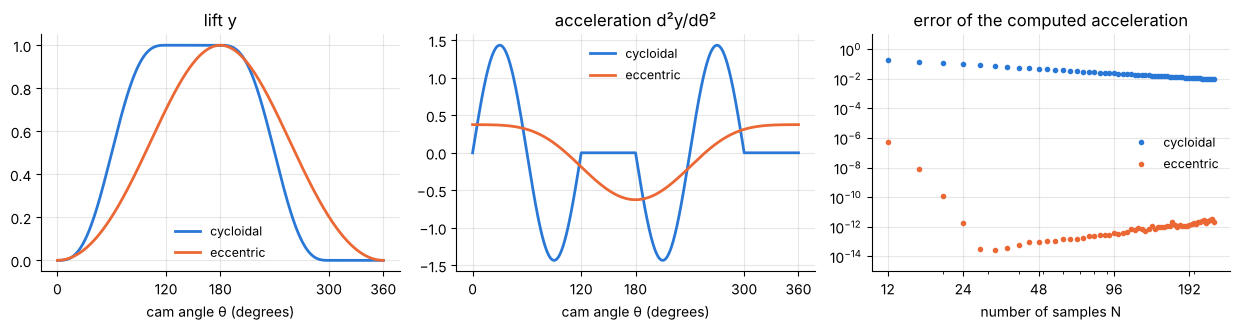

In [16]:
degrees = np.linspace(0, 360, 721)
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.4))
axes[0].plot(degrees, cycloidal_lift(np.radians(degrees)), label="cycloidal")
axes[0].plot(degrees, eccentric_lift(np.radians(degrees)), label="eccentric")
axes[0].legend(frameon=False, loc="lower center", fontsize=9)
axes[0].set(xlabel="cam angle θ (degrees)", title="lift y", xticks=[0, 120, 180, 300, 360])
axes[1].plot(degrees, cycloidal_acceleration(np.radians(degrees)), label="cycloidal")
axes[1].plot(degrees, eccentric_acceleration(np.radians(degrees)), label="eccentric")
axes[1].set(xlabel="cam angle θ (degrees)", title="acceleration d²y/dθ²", xticks=[0, 120, 180, 300, 360])
axes[1].legend(frameon=False, loc="upper center", fontsize=9)
axes[2].loglog(N_cam, cycloidal_errors, "o", ms=3, label="cycloidal")
axes[2].loglog(N_cam, eccentric_errors, "o", ms=3, label="eccentric")
axes[2].set(xlabel="number of samples N", title="error of the computed acceleration", ylim=(1e-15, 10))
axes[2].set_xticks([12, 24, 48, 96, 192], labels=["12", "24", "48", "96", "192"])
axes[2].tick_params(axis="x", which="minor", labelbottom=False)
axes[2].legend(frameon=False, loc="center right", fontsize=9)
fig.tight_layout()

Both predictions hold. With 64 samples per revolution the acceleration of the eccentric cam is
correct to twelve digits, and that of the cycloidal cam to about one and a half: an error of
up to a few per cent of the peak value, concentrated at the four angles where a dwell meets a
rise or return and largest where such an angle falls on a grid point. Doubling the number of
samples only halves it.

The lesson is not that cams with dwells are badly designed. The corners in the jerk are what a
dwell requires. The lesson is that a single Fourier representation of the whole revolution is
the wrong tool for a motion assembled from pieces. Each piece is perfectly smooth, and a
method that treats the pieces separately (the Chebyshev methods that start in notebook 4) gets
its exponential convergence back. Before applying a spectral method, ask how smooth the data
are, and where.

## Summary

- The smoother the function, the faster its Fourier coefficients decay: $|k|^{-(p+1)}$ if the
  $p$-th derivative jumps, $e^{-a|k|}$ if the function is analytic in a strip of half-width
  $a$, zero beyond $K$ if it is band-limited.
- On a grid the coefficients beyond $N/2$ are aliased onto the lower ones. The error of a
  spectral derivative is governed by those coefficients, so it inherits their decay with $k$
  replaced by $N/2$.
- For an analytic function the rate $e^{-aN/2}$ follows from the distance $a$ of the nearest
  complex singularity from the real axis. For the piston, $a = \mathrm{arccosh}(l/r)$.
- A jump in the $p$-th derivative limits the $\nu$-th spectral derivative to order
  $N^{-(p-\nu)}$.
- A jump in the function itself produces an overshoot that no refinement removes (Gibbs):
  8.95 % of the jump for the truncated series, 14.1 % for the interpolant when no grid point
  sits on the jump.

## Exercises

1. The function $u(x) = |\sin x|$ (a full-wave rectified signal) has a first derivative that
   jumps. Predict the decay order of its Fourier coefficients from the table in 3.2 and confirm
   it with `fourier_coefficients`, comparing with the exact values $c_k = \dfrac{2}{\pi(1 - k^2)}$
   for even $k$ and $c_k = 0$ for odd $k$. Then compute the largest error of
   `fft_derivative` against the exact derivative $\operatorname{sign}(\sin x)\cos x$ for
   $N = 30, 62, 126, 254$, leaving out the grid points $x = 0$ and $x = \pi$, where the
   derivative does not exist. Does it converge? Relate what you find to 3.6.
2. The function $u(x) = \dfrac{3}{5 - 4\cos x}$ has the Fourier coefficients $c_k = 2^{-|k|}$.
   (a) Where are its singularities, and what decay rate of the spectral derivative error against
   $N$ does that predict? Measure the rate and compare. (b) Use the aliasing formula to work out
   by hand the discrete amplitudes $\hat v_0/N$ and $\hat v_4/N$ on a grid of $N = 8$ points, and
   check both with `np.fft.fft`.
3. A step can be replaced by a smooth ramp: $u(x) = \tanh\big(\sin(x)/\delta\big)$ tends to the
   square wave as $\delta \to 0$. The function $\tanh z$ has its nearest singularities at
   $z = \pm i\pi/2$. For $\delta = 0.1$ find the distance $a$ of the nearest singularity of $u$
   from the real axis and predict the decay rate of the spectral derivative error. Measure the
   rate for even $N$ between 40 and 300 (divide the error by $N$ before fitting, as in 3.4), then search even $N$ up to 800 for the smallest one
   that gives an error below $10^{-8}$. How does that $N$ change if $\delta$ is halved to 0.05?
4. Replace the cycloidal rise of 3.7 by the simple harmonic rise
   $y = \tfrac12\big(1 - \cos(\pi\theta/\beta)\big)$, with the same angles ($\beta = 120°$, dwell
   to $180°$, mirror-image return to $300°$, dwell to $360°$). Which derivative of $y$ jumps?
   Predict and measure the convergence order of the spectral **velocity** $dy/d\theta$ for $N$
   from 12 to 240 in steps of 4. What happens to the computed acceleration?
5. The product $u(x) = \sin 5x\,\cos 7x$ is band-limited. Which wavenumbers does it contain?
   Find, by reasoning and then by experiment with even $N$ from 4 to 40, the smallest $N$ from
   which `fft_derivative` is exact for every larger even $N$. Explain why $N = 24$ fails
   although $f_4$ in 3.4 was already exact at $N = 16$.